# NumCompute-Stream
COMP5004 Assignment 2.2

The CSV has 2,048 generated rows. We read 64 rows at a time.
The rule for the labels changes at chunk 17.

## 1. Load the CSV
First run `python -m pip install -e .` in the project folder.
Then click **Run All** here.

`X` contains the features. `y` contains the labels.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "demo":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from demo.stream_demo import DATA, figures, log_preview
from numcompute_stream import DecisionTreeClassifier, Pipeline, StandardScaler, StreamingStats, StreamTrainer
from numcompute_stream.io import iter_supervised_csv

X, y = next(iter_supervised_csv(DATA, chunk_size=64, skip_header=1))
print("Features", X.shape)
print("Labels", y.shape)

Features (64, 2)
Labels (64,)


## 2. Train in chunks
Predict first, then update. A full buffer trains a new tree.
Try buffers of 64 and 256 rows.

In [2]:
def experiment(buffer_size):
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('tree', DecisionTreeClassifier(max_depth=5, min_samples_leaf=4, buffer_size=buffer_size)),
    ])
    trainer = StreamTrainer(pipe, window_size=256)
    stats = StreamingStats(window_size=256)
    for X, y in iter_supervised_csv(DATA, chunk_size=64, skip_header=1):
        stats.update_stats(X)
        trainer.fit_chunk(X, y)
    return trainer, stats

fast, stats = experiment(64)
slow, _ = experiment(256)
log_preview(fast)
print()
log_preview(slow)

Buffer size 64
Chunk   Accuracy    Overall  Retrain  Pending  Memory KiB
    1         --         --     True        0        8.50
    2      0.859      0.859     True        0        8.87
    4      0.875      0.839     True        0        8.32
    5      0.906      0.855     True        0        8.25
   16      0.922      0.858     True        0        8.29
   17      0.203      0.817     True        0        7.43
   18      0.922      0.824     True        0        7.43
   20      0.859      0.827     True        0        7.86
   24      0.922      0.835     True        0        7.00
   32      0.844      0.835     True        0        7.00

Buffer size 256
Chunk   Accuracy    Overall  Retrain  Pending  Memory KiB
    1         --         --    False       64        5.76
    2         --         --    False      128        7.56
    4         --         --     True        0       11.68
    5      0.906      0.906    False       64       13.54
   16      0.891      0.902     True    

## 3. Show the plots
The smaller buffer learns the new rule sooner in this example.
The final plot compares actual labels with predictions.

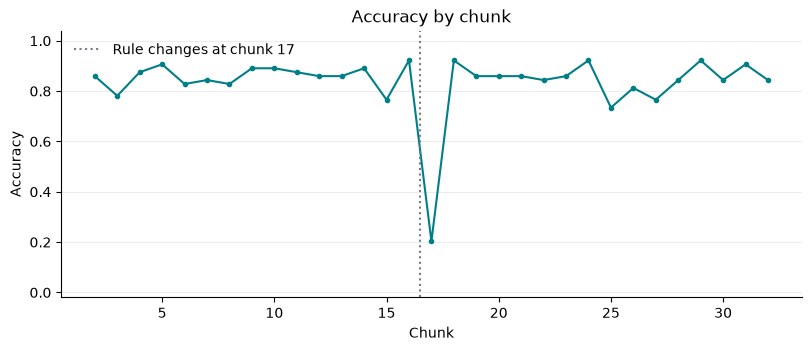

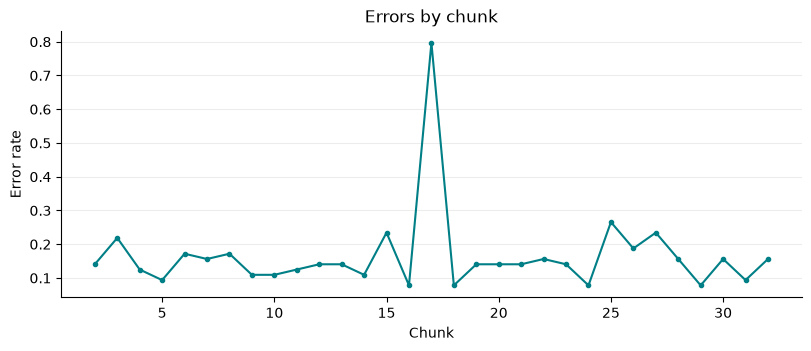

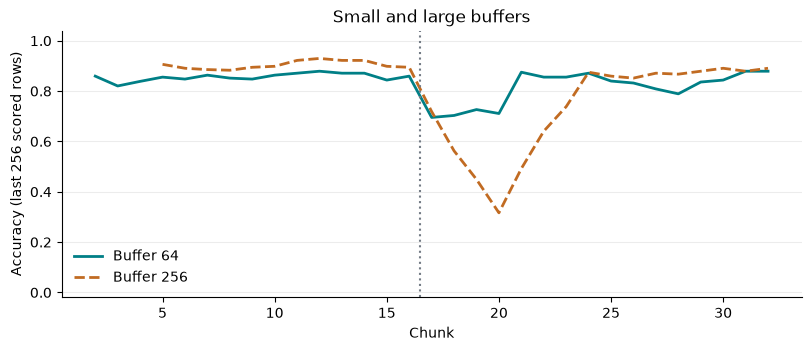

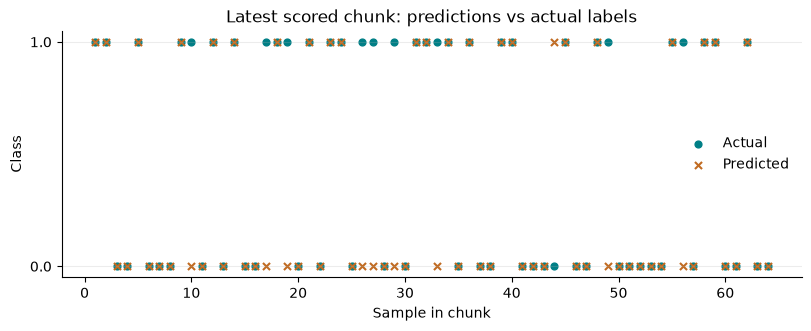

In [3]:
accuracy, error, comparison, predictions = figures(fast, slow)
for figure in (accuracy, error, comparison, predictions):
    display(figure)
    plt.close(figure)


In [4]:

result = fast.metrics.result()
print("Scored rows", result["count"])
print("Overall accuracy", round(result["accuracy"], 3))
print("AUC", round(result["auc"], 3))
print("Confusion matrix")
print(result["confusion_matrix"])

Scored rows 1984
Overall accuracy 0.835
AUC 0.879
Confusion matrix
[[811 147]
 [181 845]]


## 4. Check the code
Run `python -m unittest discover -q` in the project folder.
Run `python -m benchmark.stream_benchmark` to compare speed and buffer sizes.